# Milestone 2 - Prediksi Potensi Pembelian Sesi Kunjungan Toko Online

* **Nama:** Baihaqsani
* **Batch:** FTDS-045
* **Objective:** Membangun model klasifikasi untuk memprediksi apakah sebuah sesi kunjungan toko online berakhir dengan pembelian atau tidak, berdasarkan perilaku navigasi pengunjung.

---
# 1. Perkenalan

### Latar Belakang Masalah
* Mayoritas pengunjung yang membuka toko online tidak jadi membeli. Pada dataset ini, **10.422 dari 12.330 sesi kunjungan (84.5%)** berakhir tanpa pembelian, dan hanya **1.908 sesi (15.5%)** yang berakhir dengan transaksi.
* Akibatnya, toko kehilangan banyak potensi penjualan, dan anggaran marketing seperti promo atau voucher berisiko terbuang jika diberikan secara merata kepada semua pengunjung tanpa mengetahui siapa yang benar-benar berpotensi membeli. Hal ini semakin penting karena industri e-commerce sebagai contoh di Indonesia sudah meninggalkan strategi promo besar-besaran ("Bakar Uang") dan dituntut lebih efisien.
* Untuk mengenali sesi yang berpotensi berakhir dengan pembelian, dilakukan prediksi apakah sebuah sesi berakhir dengan pembelian atau tidak berdasarkan perilaku navigasi pengunjung.
* Harapannya, toko dapat mengetahui perilaku apa saja yang membedakan sesi yang membeli dan yang tidak membeli, sehingga hasilnya dapat menjadi dasar keputusan selanjutnya, misalnya menentukan sesi mana yang perlu diprioritaskan dalam pemberian promo.

### Gambaran Dataset 
* **Nama Dataset:** Online Shoppers Purchasing Intention Dataset 
* **Sumber:** UCI Machine Learning Repository (https://archive.ics.uci.eud/dataset/468), dibuat oleh C. Sakar dan Yomi Kastro (2018), lisensi CC BY 4.0. Paper pendukung: Sakar et al. (2019), *Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks*.
* **Ukuran:** 12.330 baris (setiap baris adalah satu sesi kunjungan dari pengguna yang berbeda dalam periode 1 tahun) dan 18 kolom.
* **Target:** `Revenue` (True = sesi berakhir dengan pembelian, False = tidak).


| Kolom | Tipe | Keterangan |
|---|---|---|
| `Administrative` | Numerik | Jumlah halaman administratif (akun, login, pengaturan) yang dibuka dalam sesi |
| `Administrative_Duration` | Numerik | Total waktu di halaman administratif (detik) |
| `Informational` | Numerik | Jumlah halaman informasi (tentang toko, kontak, kebijakan) yang dibuka |
| `Informational_Duration` | Numerik | Total waktu di halaman informasi (detik) |
| `ProductRelated` | Numerik | Jumlah halaman produk yang dibuka |
| `ProductRelated_Duration` | Numerik | Total waktu di halaman produk (detik) |
| `BounceRates` | Numerik | Rata-rata bounce rate (Google Analytics) halaman yang dikunjungi: persentase pengunjung yang masuk dari halaman itu lalu langsung pergi |
| `ExitRates` | Numerik | Rata-rata exit rate halaman yang dikunjungi: persentase tampilan halaman yang menjadi halaman terakhir dalam sesi |
| `PageValues` | Numerik | Rata-rata nilai halaman yang dikunjungi sebelum transaksi (Google Analytics) |
| `SpecialDay` | Numerik | Kedekatan waktu kunjungan dengan hari spesial (0-1), misalnya puncak 1 pada 8 Februari untuk Valentine |
| `Month` | Kategorikal | Bulan kunjungan |
| `OperatingSystems` | Kategorikal | Kode sistem operasi pengunjung (1-8) |
| `Browser` | Kategorikal | Kode browser pengunjung (1-13) |
| `Region` | Kategorikal | Kode wilayah asal pengunjung (1-9) |
| `TrafficType` | Kategorikal | Kode sumber traffic kunjungan (1-20) |
| `VisitorType` | Kategorikal | Jenis pengunjung: New_Visitor, Returning_Visitor, Other |
| `Weekend` | Kategorikal (biner) | Apakah kunjungan terjadi di akhir pekan |
| `Revenue` | Target (biner) | Apakah sesi berakhir dengan pembelian |

* Total terdapat **10 fitur numerik dan 7 fitur kategorikal**. Kolom `OperatingSystems`, `Browser`, `Region`, dan `TrafficType` disimpan sebagai angka, tetapi angkanya hanya **kode kategori** (tidak bisa dijumlahkan atau dibandingkan besar kecilnya), sehingga diperlakukan sebagai kategorikal.
* **Keterbatasan dataset:** arti setiap kode pada `OperatingSystems`, `Browser`, `Region`, dan `TrafficType` tidak dipubilkasikan oleh pembuat dataset, dan nama toko online asa data juga tidak disebutkan.

### Objective 
* Memahami perilaku navigasi yang membedakan sesi yang berakhir dengan pembelian dan yang tidak.
* Membangun model klasifikasi dengan 5 algoritma (KNN, SVM, Decision Tree, Random Forest, dan adaBoost) di dalam Pipeline, membandingkannya dengan cross validation, lalu melakukan hyperparameter tuning pada model terbaik.
* Menghasilkan model ke dalam aplikasi web.

### Metrik Evaluasi
* **Metrik utama: F1-score kelas 1 (membeli).** Data imbalanced (15.5% membeli), sehingga accuracy menyesatkan. F1-score menyeimbangkan dua kepentingan bisnis:
    * **Recall:** Berapa banyak sesi pembeli yang berhasil dikenali (False Negative = calon pembeli terlewat).
    * **Precision:** Dari sesi yang diprediksi membeli, berapa yang benar-benar membeli (False Positive = promo terbuang).
* **Metrik Pendamping:** recall, precision, dan ROC-AUC (kemampuan model untuk dapat membedakan kelas di semua threshold).

### User
* Tim marketing atau CRM toko online yang mencatat aktivitas pengunjung menggunakan Google Analytics dan memiliki attribut data yang sama seperti dataset ini, untuk menentukan sesi kunjungan mana yang perlu diprioritaskan dalam pemberian promo.

---
# 2. Import Libraries

In [1]:
# Library untuk manipulasi data & menyimpan model
import pandas as pd
import numpy as np
import pickle
import json

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk uji statistik (EDA & feature selection)
from scipy.stats import spearmanr, chi2_contingency

# Library untuk feature engineering & pipeline
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from feature_engine.outliers import Winsorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline

# Library untuk model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# library untuk metrik evaluasi 
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score, 
                            recall_score, precision_score, f1_score, precision_recall_curve)

---
# 3. Data Loading

* Membaca dataset `online_shoppers_intention.csv` yang diunduh dari UCI Machine Learning Repository.

In [2]:
# Memuat dataset
df = pd.read_csv('../src/online_shoppers_intention.csv')

# Cek ukuran dataset (baris, kolom)
print(f'Ukuran dataset: {df.shape}')

Ukuran dataset: (12330, 18)


### Menampilkan Head & Tail 10 Data

In [3]:
# Menampilkan 10 data pertama dan 10 data terakhir
display(df.head(10))
display(df.tail(10))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12320,0,0.00,0,0.0,8,143.583333,0.014286,0.050000,0.000000,0.0,Nov,2,2,3,1,Returning_Visitor,False,False
12321,0,0.00,0,0.0,6,0.000000,0.200000,0.200000,0.000000,0.0,Nov,1,8,4,1,Returning_Visitor,False,False
12322,6,76.25,0,0.0,22,1075.250000,0.000000,0.004167,0.000000,0.0,Dec,2,2,4,2,Returning_Visitor,False,False
12323,2,64.75,0,0.0,44,1157.976190,0.000000,0.013953,0.000000,0.0,Nov,2,2,1,10,Returning_Visitor,False,False
12324,0,0.00,1,0.0,16,503.000000,0.000000,0.037647,0.000000,0.0,Nov,2,2,1,1,Returning_Visitor,False,False
12325,3,145.00,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.00,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.00,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.00,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.00,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


### Cek Tipe Data

In [4]:
# Cek tipe data dan jumlah data non-null setiap kolom
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

* Dataset terdiri dari 18 kolom: 7 kolom integer, 7 kolom float, 2 kolom teks (`Month`, `VisitorType`), dan 2 kolom boolean (`Weekend`, `Revenue`).
* Kolom `OperatingSystems`, `Browser`, `Region`, dan `TrafficType` terbaca sebagai integer, padahal isinya kode kategori. Tipe datanya akan disesuaikan.

### Cek Nilai Unik Kolom Kategorikal

In [5]:
# Cek nilai unik pada kolom kategorikal
for col in ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    print(f'{col} ({df[col].nunique()} kategori):', sorted(df[col].unique().tolist(), key=str))

Month (10 kategori): ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
VisitorType (3 kategori): ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend (2 kategori): [False, True]
OperatingSystems (8 kategori): [1, 2, 3, 4, 5, 6, 7, 8]
Browser (13 kategori): [1, 10, 11, 12, 13, 2, 3, 4, 5, 6, 7, 8, 9]
Region (9 kategori): [1, 2, 3, 4, 5, 6, 7, 8, 9]
TrafficType (20 kategori): [1, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 2, 20, 3, 4, 5, 6, 7, 8, 9]


* Kolom `Month` hanya berisi **10 bulan**, karena data bulan **Januari dan April tidak ada** di dataset. Hal ini perlu diingat saat membaca tren bulanan.
* Penulisan bulan tidak konsisten, Juni ditulis `June`, sedangkan bulan lain ditulis dengan 3 huruf saja (`Feb`, `Mar`, dst).

### Penyesuaian Data
* `June` diganti menjadi `Jun` agar konsisten dengan penulisan bulan lainnya.
* `OperatingSystems`, `Browser`, `Region`, dan `TrafficType` diubah menjadi string supaya diperlakukan sebagai kategori, bukan angka.
* `Weekend` dan `Revenue` diubah dari boolean menjadi integer (1 = True, 0 = False) agar mudah dihitung dan dipakai model.

In [6]:
# Samakan penulisan bulan
df['Month'] = df['Month'].replace('June', 'Jun')

# Ubah kolom kode kategori menjadi string
code_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
df[code_cols] = df[code_cols].astype(str)

# Ubah kolom boolean menjadi integer
ints_cols = ['Weekend', 'Revenue']
df[ints_cols] = df[ints_cols].astype(int)

df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems            object
Browser                     object
Region                      object
TrafficType                 object
VisitorType                 object
Weekend                      int64
Revenue                      int64
dtype: object

### Statistik Deskriptif

In [7]:
# Statistik deskriptif kolom numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


**Insight Statistik Deskriptif:**
* * Hampir semua kolom numerik memiliki rata-rata yang jauh di atas median, artinya distribusinya **right-skewed**. Contohnya `ProductRelated_Duration` : Median 599 detik (±10 menit), rata-rata 1. 195 detik, dan nilai maksimum 63.974 detik (±17.8 jam, kemungkinan tab browser yang dibiarkan terbuka).
* Pengunjung rata-rata membuka 31.7 halaman produk, tetapi mediannya hanya 18 halaman. Sebagian kecil sesi membuka ratusan halaman (maksimum 705).
* Kuartil ke-3 (75%) dari `Informational`,  `Informational_Duration`, `PageValues`, dan `SpecialDay` bernilai 0. Artinya **Lebih dari 75% sesi** tidak membuka halaman informasi, tidak mengunjungi halaman yang bernilai (PageValues = 0), dan tidak terjadi di dekat hari spesial.
* `BouncesRates` dan `ExitRates` berada di rentang 0 - 0.2.

* Rata-rata `Weekend` 0.23 berarti 23% sesi terjadi di akhir pekan, dan rata-rata `Revenue` 0.15 berarti 15% sesi berakhir dengan pembelian.

### Cek Missing Values & Duplikat

In [8]:
# Cek Missing Value 
print(df.isnull().sum(), '\n')

# Cek Duplicated 
print(f'Jumlah data duplikat : {df.duplicated().sum()}')

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64 

Jumlah data duplikat : 125


In [9]:
# Cek karakteristik baris duplikat
duplicate_rows = df[df.duplicated(keep=False)]
print('Jumlah baris yang terlibat duplikat:', len(duplicate_rows))
print('Distribusi target pada baris duplikat:', duplicate_rows['Revenue'].value_counts().to_dict())
duplicate_rows[['ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'Revenue']].value_counts().head()

Jumlah baris yang terlibat duplikat: 201
Distribusi target pada baris duplikat: {0: 201}


ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  PageValues  Revenue
1               0.0                      0.2          0.2        0.0         0          189
2               0.0                      0.2          0.2        0.0         0           12
Name: count, dtype: int64

**Justifikasi Data Duplikat:**
* Terdapat 125 baris duplikat (201 baris terlibat). Seluruhnya adalah sesi yang **tidak membeli** dengan pola sangat sederhana: membuka 1-2 halaman produk, durasi 0 detik, `BounceRates` dan `ExitRates` 0.2 serta `PageValues` 0. Ini adalah pola sesi bounce (masuk langsung keluar).
* Duplikat ini **tidak dihapus**, dengan alasan:
    * Menurut keterangan dataset di UCI, setiap baris adalah sesi dari pengguna yang berbeda.
    * Sesi bounce hanya memiliki sedikit variasi nilai, sehingga sangat wajar jika beberapa pengunjung berbeda memiliki nilai yang identik.
    * Menghapusnya justru membuat perilaku bounce yang nyata menjadi kurang terwakili. Jumlahnya juga hanya 1% dari data.

---
# 4. Exploratory Data Analysis (EDA)

###  4.1 Distribusi Target 
* Melihat proporsi kelas target untuk menentukan metrik evaluasi yang tepat.

Revenue
0    10422
1     1908
Name: count, dtype: int64
Revenue
0    84.53
1    15.47
Name: proportion, dtype: float64


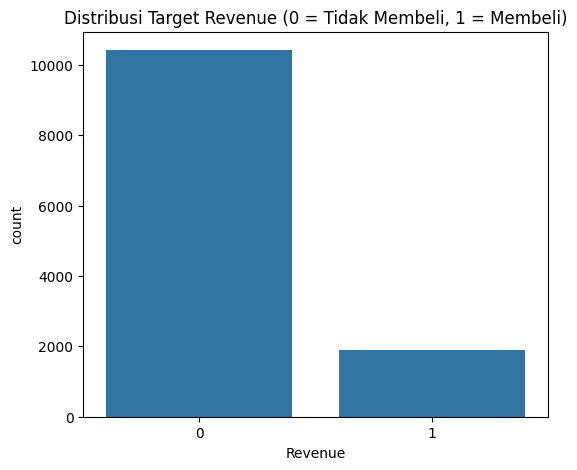

In [10]:
# Cek distribusi target
print(df['Revenue'].value_counts())
print((df['Revenue'].value_counts(normalize=True)*100).round(2))

# Visualisasi distribusi target
plt.figure(figsize=(6,5))
sns.countplot(x='Revenue', data=df)
plt.title('Distribusi Target Revenue (0 = Tidak Membeli, 1 = Membeli)')
plt.show()

**Insight Distribusi Target:**
* Target **imbalanced** : hanya 15.47% (1.908 sesi) yang berakhir dengan pembelian, sedangkan 84.53% (10.422 sesi) tidak membeli.
* Model yang selalu menebak "tidak membeli" pun sudah mendapat accuracy 84.53%. Karena itu, accuracy tidak dipakai sebagai metrik utama, melainkan F1-score, recall, precision, dan ROC-AUC.
* Implikasi untuk modeling : split data memakai `stratify`, dan penanganan imbalance (`class_weight`) dicoba saat hyperparameter tuning

### 4.2 Bagaimana perilaku navigasi halaman produk pada sesi yang membeli dan yang tidak membeli?

In [11]:
# Kolom perilaku navigasi yang dibandingkan
nav_cols = ['ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']

# Bandingkan median setiap fitur antara sesi tidak membeli (0) dan membeli (1)
df.groupby('Revenue')[nav_cols].median().round(3)

,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
Revenue,,,,
0,16.0,510.190,0.004,0.029
1,29.0,1109.906,0.000,0.016


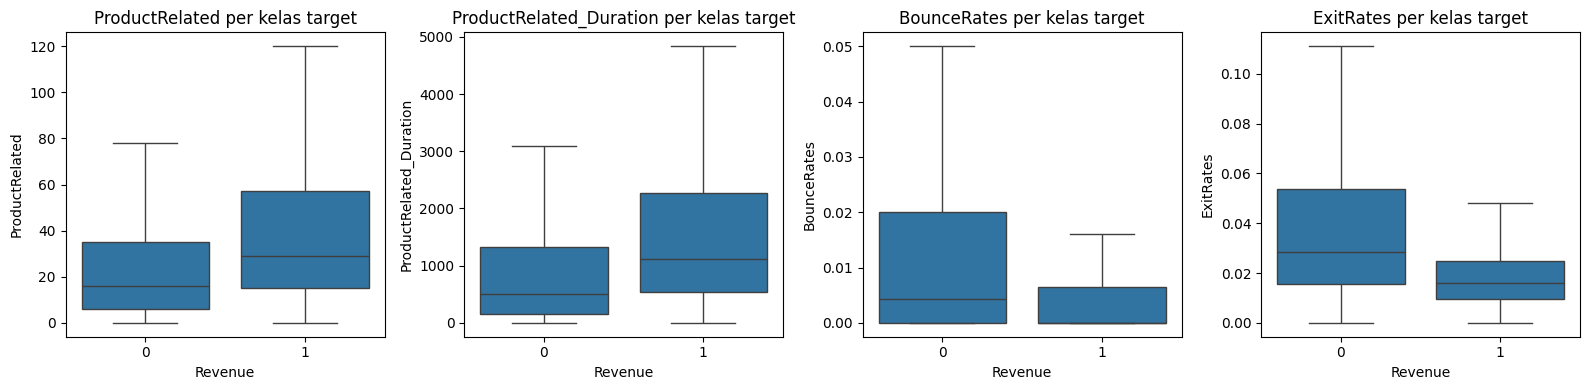

In [12]:
# Boxplot distribusi setiap fitur berdasarkan kelas target
plt.figure(figsize=(16,4))
for i, col in enumerate(nav_cols):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(x='Revenue', y=col, data=df, showfliers=False)
    plt.title(f'{col} per kelas target')
plt.tight_layout()
plt.show()

**Insight Perilaku Navigasi**:
* Sesi yang membeli membuka **median 29 halaman produk**, hampir 2x lebih banyak dibanding sesi yang tidak membeli (16 halaman).
* Waktu di halaman produk juga **±2,2x lebih lama**: median 1.110 detik (±18,5 menit) vs 510 detik (±8,5 menit).
* Sesi yang membeli memiliki `ExitRates` lebih rendah (median 0.016 vs 0.029) dan `BounceRates` median 0. Artinya pembeli mengunjungi halaman-halaman yang jarang menjadi titik keluar pengunjung.
* **Implikasi bisnis** : keterlibatan di halaman produk (jumlah dan durasi) adalah sinyal niat beli. Sesi yang menjelajahi banyak produk dalam waktu lama layak diprioritaskan, sedangkan halaman dengan exit rate tinggi perlu dievaluasi tampilannya.

### 4.3 Seberapa besar pengaruh `PageValues` terhadap pembelian?

,jumlah sesi,jumlah pembelian,conversion rate
PageValues_group,,,
PageValues = 0,9600,370,3.9
PageValues > 0,2730,1538,56.3


Persentase pembeli dengan PageValues > 0: 80.6 %


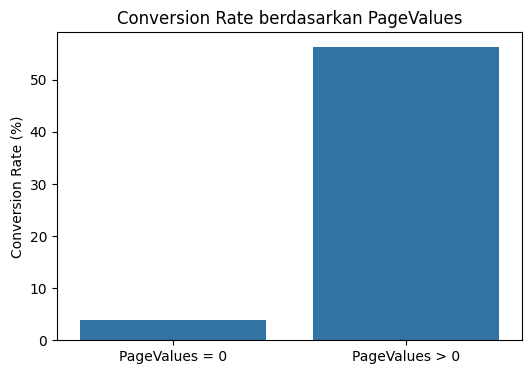

In [13]:
# Kelompokkan sesi berdasarkan ada/tidaknya PageValues
df_pv = df.copy()
df_pv['PageValues_group'] = np.where(df_pv['PageValues'] > 0, 'PageValues > 0', 'PageValues = 0')

# Jumlah sesi dan conversion rate setiap kelompok
pv_summary = df_pv.groupby('PageValues_group')['Revenue'].agg(['count', 'sum', 'mean'])
pv_summary.columns = ['jumlah sesi', 'jumlah pembelian', 'conversion rate']
pv_summary['conversion rate'] = (pv_summary['conversion rate'] * 100).round(1)
display(pv_summary)

# Persentase pembeli yang memiliki PageValues > 0
print('Persentase pembeli dengan PageValues > 0:', round(df[df['Revenue'] == 1]['PageValues'].gt(0).mean() * 100, 1), '%')

# Visualisasi conversion rate
plt.figure(figsize=(6,4))
sns.barplot(x=pv_summary.index, y=pv_summary['conversion rate'])
plt.title('Conversion Rate berdasarkan PageValues')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('')
plt.show()

**Insight PageValues**:
* Sesi yang mengunjungi halaman bernilai (`PageValues` > 0) memiliki conversion rate **56.3%**, sedangkan sesi dengan `PageValues` = 0 hanya **3.9%** (±14x lebih rendah).
* Sebanyak **80.6% pembeli** mengunjungi minimal satu halaman bernilai.
* `PageValues` adalah sinyal paling kuat karena nilainya dihitung Google Analytics dari halaman yang biasanya dilewati sebelum transaksi (misalnya halaman keranjang). Hal ini juga menjadi catatan: model kemungkinan akan sangat bergantung pada fitur ini, sehingga akan diuji lebih lanjut di bagian Model Evaluation.

### 4.4 Bagaimana tren jumlah kunjungan dan conversion rate setiap bulan?

Month,Feb,Mar,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
jumlah sesi,184.0,1907.0,3364.0,288.0,432.0,433.0,448.0,549.0,2998.0,1727.0
conversion rate,1.6,10.1,10.9,10.1,15.3,17.6,19.2,20.9,25.4,12.5


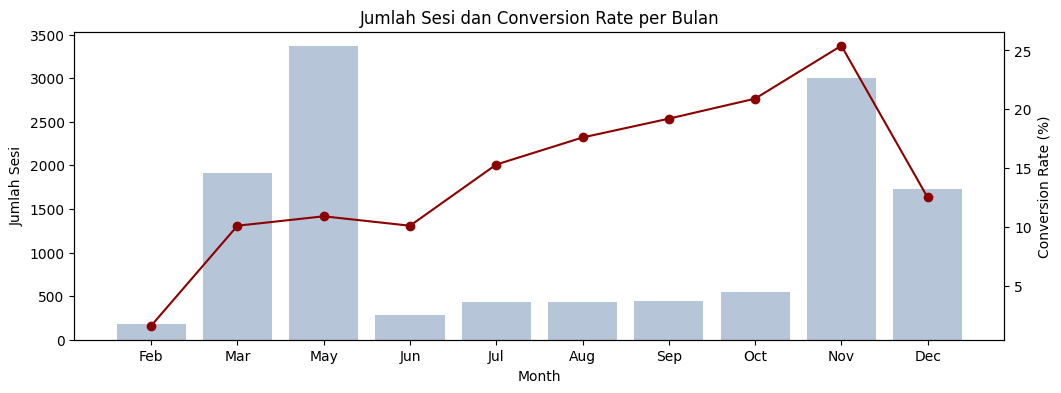

In [14]:
# Urutan bulan sesuai dengan kalender (Januari & April tidak ada di dataset)
month_order = ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Jumlah sesi dan conversion rate per bulan
month_summary = df.groupby('Month')['Revenue'].agg(['count', 'mean']).reindex(month_order)
month_summary.columns = ['jumlah sesi', 'conversion rate']
month_summary['conversion rate'] = (month_summary['conversion rate'] * 100).round(1)
display(month_summary.T)

# Visualisasi: bar = jumlah sesi, line = conversion rate
fig, ax1 = plt.subplots(figsize=(12,4))
sns.barplot(x=month_summary.index, y=month_summary['jumlah sesi'], color='lightsteelblue', ax=ax1)
ax1.set_ylabel('Jumlah Sesi')
ax2 = ax1.twinx()
ax2.plot(range(len(month_summary)), month_summary['conversion rate'], color='darkred', marker='o')
ax2.set_ylabel('Conversion Rate (%)')
plt.title('Jumlah Sesi dan Conversion Rate per Bulan')
plt.show()

**Insight Tren Bulanan:**
* **November** memiliki conversion rate tertinggi (**25.4%**) dengan jumlah kunjungan terbanyak kedua (2.998 sesi), diikuti Oktober (20.9%) dan September (19.2%). Kuartal 4 adalah momen pengunjung paling siap membeli, sejalan dengan temuan Milestone sebelumnya tetang pentingnya strategi promo Q4.
* **Mei** memiliki kunjungan terbanyak (3.364 sesi), tetapi conversion rate-nya hanya 10.9%. Traffic tinggi belum tentu menghasilkan penjualan.
* **Februari** memiliki conversion rate terendah (1.6%) dengan kunjungan paling sedikit (184 sesi).
* Desember justru turun ke 12.5% walaupun musim liburan.
* Catatan: data Januari dan April tidak tersedia, sehingga tren tahunan tidak lengkap.
* **Implikasi Bisnis:** anggaran promo lebih efektif dialokasikan pada September-November, sedangkan pada bulan dengan traffic tinggi tetapi conversion rendah (Mei, Maret) perlu strategi untuk mengubah pengunjung menjadi pembeli. 

### 4.5 Korelasi antar Fitur Numerik

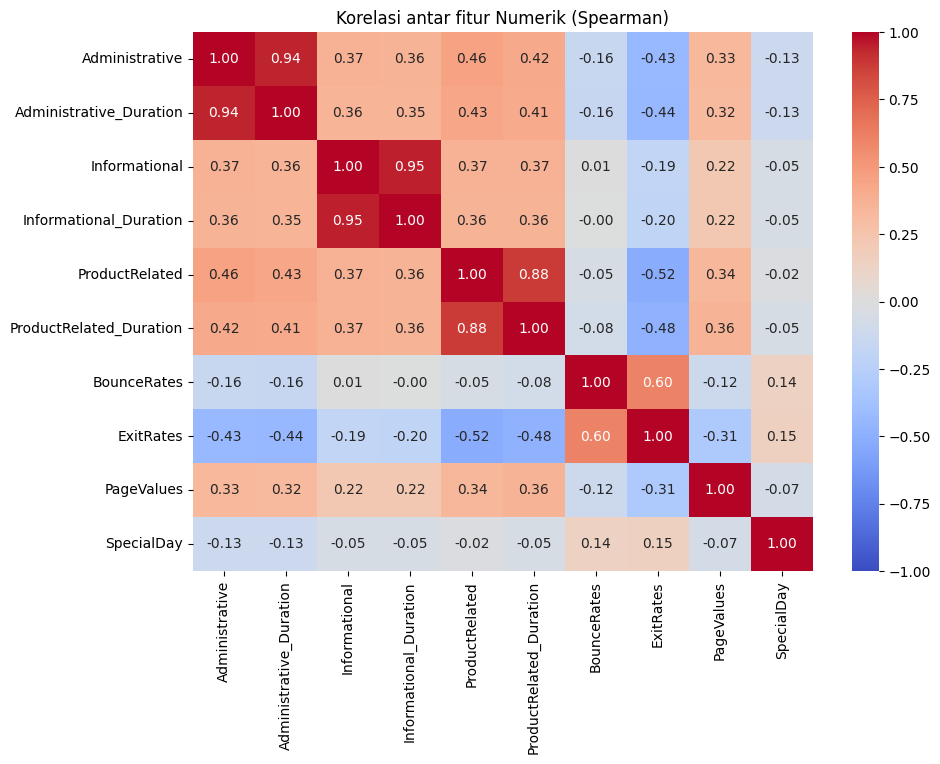

In [15]:
# Kolom numerik
num_cols_all = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
               'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay' ]

# Heatmap korelasi Spearman (dipkaai karena distribusi fitur skewed)
plt.figure(figsize=(10,7))
sns.heatmap(df[num_cols_all].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar fitur Numerik (Spearman)')
plt.show()

**Insight Korelasi:**
* Jumlah halaman dan durasinya berkorelasi sangat kuat : `Administrative` - `Administrative_Duration` (0.94), `Informational` - `Informational_Duration` (0.95), dan `ProductRelated` - `ProductRelated_Duration` (0.88). Hal ini wajar karena makin banyak halaman yang dibuka, makin lama waktunya.
* `BounceRates` dan `ExitRates` juga berkorelasi (0.60), karena keduanya mengukur pengunjung yang meninggalkan website.
* Fitur yang saling berkorelasi kuat akan dicek ulang di bagian Feature Selection untuk menghindari informasi ganda. 

### Kesimpulan EDA
1. Target imbalanced (15.5% membeli), sehingga metrik utama yang dipakai adalah F1-score, bukan accuracy.
2. **Perilaku navigasi membedakan pembeli dan bukan pembeli:** pembeli membuka ±2x lebih banyak halaman produk, menghabiskan ±2,2x lebih lama di halaman produk, dan memiliki exit rate lebih rendah.
3. **``PageValues`` adalah sinyal terkuat:** conversion 56.3% saat `PageValues` > 0 vs 3.9% saat 0.
4. **Waktu kunjungan berpengaruh:** November memiliki conversion tertinggi (25.4%), sedangkan Mei memiliki kunjungan terbanyak tetapi conversion-nya hanya 10.9%.
5. **Jumlah halaman dan durasinya saling berkorelasi kuat**, begitu juga `BounceRates` dan `ExitRates`, sehingga perlu dicek ulang saat Feature Selection.

---
# 5. Feature Engineering

### 5.1 Split between X and y, lalu Train-Set and Test-Set
* Split dilakukan sebelum proses feature engineering lainnya agar tidak terjadi data leakage. Seluruh perhitungan (batas outlier, daftar kategori, uji statistik) hanya memakai train-set.
* Menggunakan `stratify=y` supaya proporsi kelas membeli (±15.5%) sama di train-set dan test-set.

In [16]:
# Split between X and y
X =df.drop('Revenue', axis=1)
y = df['Revenue']

# Split between Train-Set and Test-Set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Train Size:', X_train.shape)
print('Test Size:', X_test.shape)
print('Proporsi kelas 1 - Test :', round(y_train.mean(),4))
print('Proporsi kelas 1 - Test :', round(y_test.mean(),4))

Train Size: (9864, 17)
Test Size: (2466, 17)
Proporsi kelas 1 - Test : 0.1547
Proporsi kelas 1 - Test : 0.1549


### 5.2 Handling Cardinality

In [17]:
# Cek cardinality kolom kategorikal
cat_cols_all = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

listItem = []
for col in cat_cols_all:
    listItem.append([col, X_train[col].nunique(), X_train[col].value_counts().to_dict()])

pd.set_option('display.max_colwidth', 200)
pd.DataFrame(columns=['nama kolom', 'jumlah nilai unique', 'jumlah data per kategori'], data=listItem)

,nama kolom,jumlah nilai unique,jumlah data per kategori
0,Month,10,"{'May': 2703, 'Nov': 2360, 'Mar': 1538, 'Dec': 1391, 'Oct': 444, 'Sep': 368, 'Jul': 344, 'Aug': 342, 'Jun': 228, 'Feb': 146}"
1,VisitorType,3,"{'Returning_Visitor': 8443, 'New_Visitor': 1347, 'Other': 74}"
2,OperatingSystems,8,"{'2': 5275, '1': 2063, '3': 2050, '4': 383, '8': 67, '6': 17, '5': 5, '7': 4}"
3,Browser,13,"{'2': 6361, '1': 1959, '4': 596, '5': 382, '6': 140, '10': 135, '8': 107, '3': 83, '13': 52, '7': 36, '12': 7, '11': 5, '9': 1}"
4,Region,9,"{'1': 3782, '3': 1951, '4': 937, '2': 924, '6': 643, '7': 606, '9': 413, '8': 337, '5': 271}"
5,TrafficType,20,"{'2': 3135, '1': 1934, '3': 1654, '4': 866, '13': 581, '10': 370, '6': 350, '8': 268, '5': 215, '11': 195, '20': 156, '7': 35, '9': 33, '15': 33, '19': 13, '14': 12, '18': 9, '16': 3, '12': 1, '17..."


* `Month` (10 kategori) dan `VisitorType` (3 kategori) termasuk low cardinality, dan semua kategori `Region` memiliki data yang cukup banyak (minimal 271 baris).
* `OperatingSystems` (8), `Browser` (13), dan `TrafficType` (20) memiliki beberapa kategori yang sangat jarang muncul, bahkan ada yang hanya 1 baris (Browser 9, TrafficType 12 dan 17).
* Kategori yang muncul **kurang dari 100 kali di train-set (±1% data)** digabung menjadi '`Other`'. Kategori yang terlalu jarang membuat kolom one-hot hampir selalu bernilai 0 dan pola conversion-nya tidak dapat dipercaya. Daftar kategori dihitung dari train-set saja dan akan disimpan untuk dipakai ulang saat inference.

In [18]:
# Simpan dafta kategori yang muncul minimal 100 kali - dihitung dari train-set saja
top_os = X_train['OperatingSystems'].value_counts()[lambda x: x >= 100].index.tolist()
top_browser = X_train['Browser'].value_counts()[lambda x: x >= 100].index.tolist()
top_traffic = X_train['TrafficType'].value_counts()[lambda x: x >= 100].index.tolist()

# Kategori lain digabung menjadi 'Other' (train-set & test-set)
for df_ in [X_train, X_test]:
    df_['OperatingSystems'] = np.where(df_['OperatingSystems'].isin(top_os), df_['OperatingSystems'], 'Other')
    df_['Browser'] = np.where(df_['Browser'].isin(top_browser), df_['Browser'], 'Other')
    df_['TrafficType'] = np.where(df_['TrafficType'].isin(top_traffic), df_['TrafficType'], 'Other')

print('Kategori OperatingSystems :', sorted(X_train['OperatingSystems'].unique().tolist()))
print('Kategori Browser :', sorted(X_train['Browser'].unique().tolist()))
print('Kategori TrafficType :', sorted(X_train['TrafficType'].unique().tolist()))

Kategori OperatingSystems : ['1', '2', '3', '4', 'Other']
Kategori Browser : ['1', '10', '2', '4', '5', '6', '8', 'Other']
Kategori TrafficType : ['1', '10', '11', '13', '2', '20', '3', '4', '5', '6', '8', 'Other']


### 5.3 Handling Missing Values

In [19]:
# Cek missing values pada train-set dan test-set
print('Train-Set :', X_train.isnull().sum().sum())
print('Test-Set :', X_test.isnull().sum().sum())

Train-Set : 0
Test-Set : 0


**Justifikasi Handling Missing Values:**
* Tidak ada missing values pada train-set maupun test-set, sesuai keterangan dataset di UCI.
* Walaupun begitu, `SimpleImputer` tetap dipasang di dalam Pipeline (median untuk menarik, modus untuk kategorikal) sebagai pengaman jika ada data kosong saat inference atau saat model dipakai di aplikasi.

### 5.4 Handling Outliers
* Dua fungsi berikut mengikuti materi Feature Engineering:
    * `outlier_table()` : menentukan distribusi (normal/skewed) dari skewness, menghitung batas atas dan bawah, lalu menghitung persentase outlier. Fungsi ini juga menampilkan nilai IQR, karena kolom dengan IQR = 0 tidak bisa di-capping dengan metode IQR.
    * `diagnostic_plots()` : menampilkan histogram dan boxplot sebuah kolom.

In [20]:
# Fungsi untuk menghitung skewness, IQR, batas-outlier, dan persentase outlier
def outlier_table(df, columns):
    column, skew_value, iqr_value, distribution, lower_bound, upper_bound, percent_outlier = [], [], [], [], [], [], []

    for col in columns:
        skew = round(df[col].skew(), 1)
        IQR = df[col].quantile(0.75) - df[col].quantile(0.25)
        if -0.5 <= skew <= 0.5:
            dist = 'normal'
            lower_boundary = df[col].mean() - 3 * df[col].std()
            upper_boundary = df[col].mean() + 3 * df[col].std()
        else:
            dist = 'skewed'
            lower_boundary = df[col].quantile(0.25) - (IQR * 3)
            upper_boundary = df[col].quantile(0.75) + (IQR * 3)

        total_outlier = ((df[col] > upper_boundary).sum() + (df[col] < lower_boundary).sum()) / len(df) * 100  

        column.append(col)
        skew_value.append(skew)
        iqr_value.append(round(IQR, 4))
        distribution.append(dist)
        lower_bound.append(round(lower_boundary, 4))
        upper_bound.append(round(upper_boundary, 4))
        percent_outlier.append(round(total_outlier, 2))

    return pd.DataFrame({
        'nama kolom': column,
        'skewness': skew_value,
        'IQR': iqr_value,
        'distribusi' : distribution,
        'lower_boundary' : lower_bound,
        'upper_boundary' : upper_bound,
        'persentase outlier (%)' : percent_outlier
    })

# Fungsi histogram & boxplot untuk melhat distribusi
def diagnostic_plots(df, variable):
    plt.figure(figsize=(16,4))

    plt.subplot(1, 2, 1)
    sns.histplot(df[variable], bins=30)
    plt.title(f'Histogram - {variable}')

    plt.subplot(1, 2, 2)
    sns.boxplot(y=df[variable])
    plt.title(f'Boxplot - {variable}')

    plt.show()

In [21]:
# Cek skewness, IQR, batas outlier, dan persentase fitur numerik (train-set)
outlier_table(X_train, num_cols_all)

,nama kolom,skewness,IQR,distribusi,lower_boundary,upper_boundary,persentase outlier (%)
0,Administrative,2.0,4.0000,skewed,-12.0000,16.0000,0.41
1,Administrative_Duration,5.7,93.0000,skewed,-279.0000,372.0000,4.51
2,Informational,4.1,0.0000,skewed,0.0000,0.0000,21.46
3,Informational_Duration,7.7,0.0000,skewed,0.0000,0.0000,19.53
4,ProductRelated,4.4,31.0000,skewed,-86.0000,131.0000,3.24
5,ProductRelated_Duration,8.0,1291.9423,skewed,-3693.2607,5350.3351,3.01
6,BounceRates,2.9,0.0171,skewed,-0.0512,0.0683,8.60
7,ExitRates,2.1,0.0357,skewed,-0.0929,0.1571,6.44
8,PageValues,6.2,0.0000,skewed,0.0000,0.0000,22.23
9,SpecialDay,3.3,0.0000,skewed,0.0000,0.0000,10.28


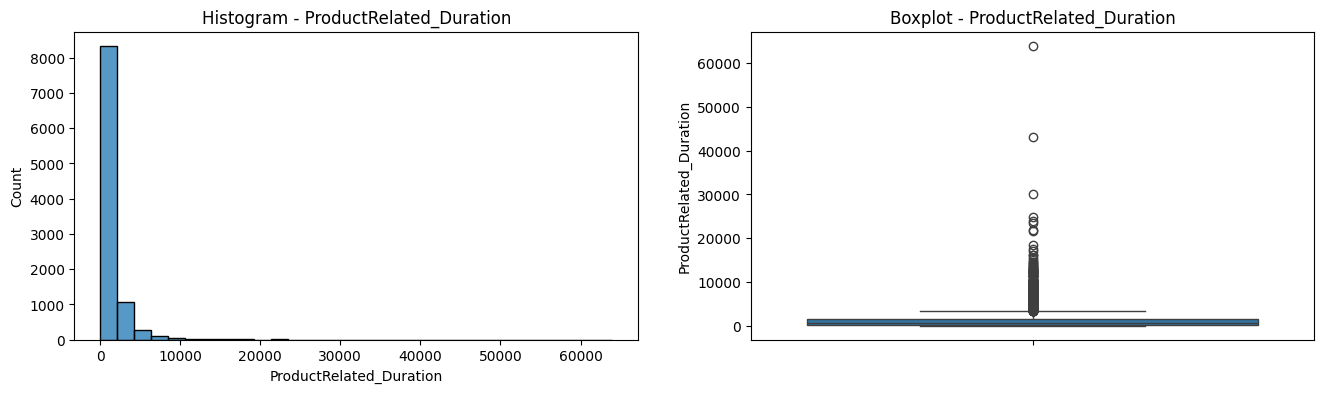

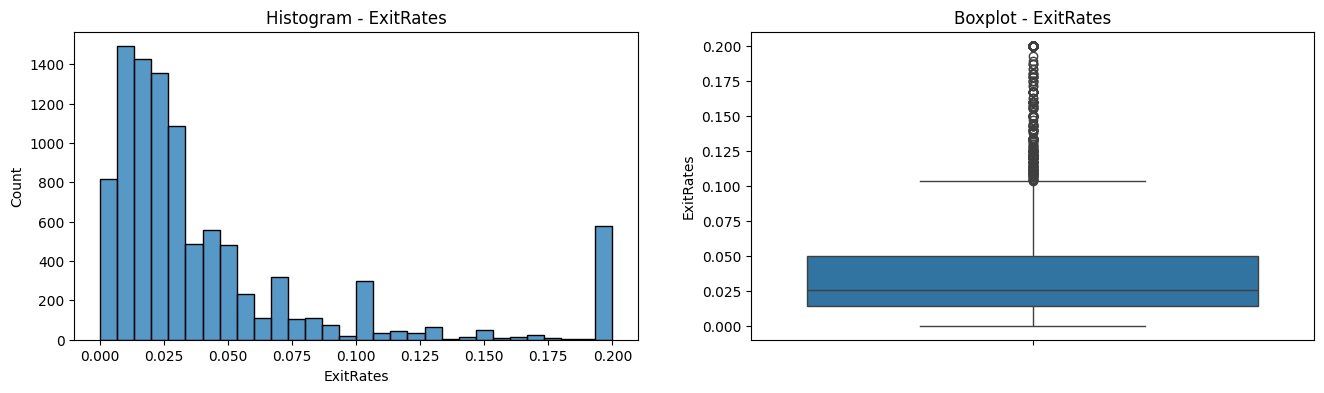

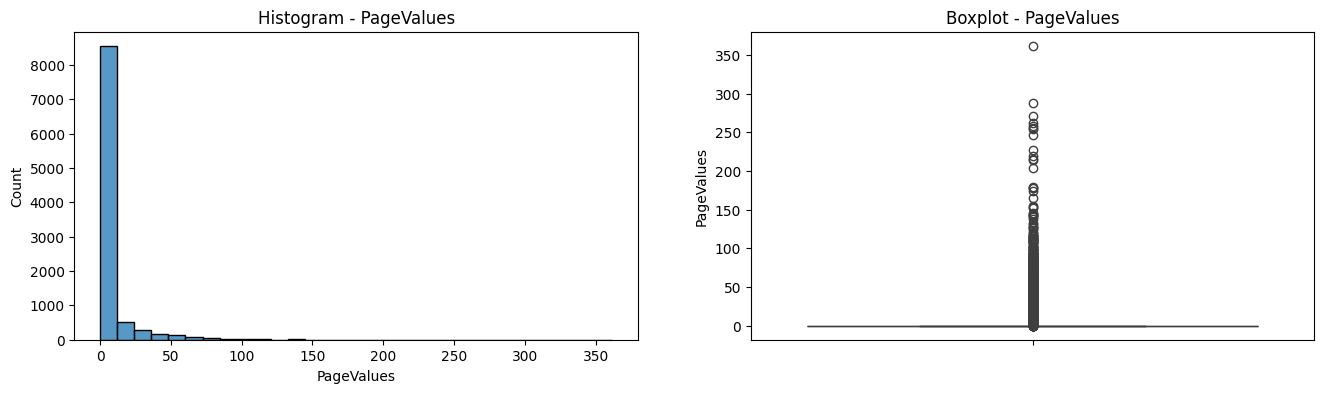

In [22]:
for col in ['ProductRelated_Duration', 'ExitRates', 'PageValues']:
    diagnostic_plots(X_train, col)

**Justifikasi Penanganan Outlier:**
* Kesepuluh fitur numerik memiliki distribusi **skewed** (skewness 2.0 - 8.0), sehingga batas outlier dihitung dengan metode IQR (fold=3).
* **Fitur yang tidak di-capping:** `informational`, `informational_Duration`, `PageValues`, dan `SpecialDay`. **Keempatnya memiliki IQR = 0 karena lebih dari 75% nilainya 0, sehingga batas atasnya juga 0. Jika di-capping, seluruh nilai di atas 0 akan berubah menjadi 0 dan informasinya hilang. Contohnya `PageValues`, yang menurut EDA membedakan conversion 56.3% vs 3.9%. Nilai di atas 0 pada fitur ini bukan kesalahan data, melainkan perilaku pengunjung yang nyata.
* **Fitur yang di-capping:** `Administrative`, `Administrative_Duration`, `ProductRelated`,`ProductRelated_Duration`, dan `ExitRates`** (`BounceRates` tidak termasuk karena di-drop pada Feature Selection). Persentase outlier-nya 0.4% - 6.4%.
* Dipilih **capping (Winsorizer, `capping_method='iqr'`, `fold=3`)**, bukan trimming, karena nilai ekstrem tetap merupakan sesi yang nyata (misalnya sesi yang sangat lama) dan trimming akan membuang data. Capping meredam nilai ekstrem yang dapat mendistorsi model berbasis jarak seperti KNN dan SVM.
* Winsorizer dimasukkan ke dalam Pipeline agar batasnya hanya dipelajari dari train-set, dan dihitung ulang pada setiap fold cross validation.

### 5.5 Feature Selection
* Uji korelasi Spearman untuk fitur numerik (dipakai karena distribusinya skewed dan targetnya biner) dan uji Chi-Square untuk fitur kategorikal terhadap target, lalu mengecek multikolinearitas antar fitur numerik.

In [23]:
# Feature Selection numerik: uji korelasi Spearman terhadap target (train-set)
num_cand = num_cols_all + ['Weekend']

p_values, corr_values, interpretasi, cols = [], [], [], []

for col in num_cand:
    corr_coef, p_value = spearmanr(X_train[col], y_train)

    cols.append(col)
    corr_values.append(round(corr_coef, 3))
    p_values.append(p_value)
    interpretasi.append('ada korelasi' if p_value < 0.05 else 'tidak ada korelasi')

pd.DataFrame({
    'nama kolom': cols,
    'koefisien korelasi': corr_values,
    'p-value': p_values,
    'hasil': interpretasi
}).sort_values('koefisien korelasi', key=abs, ascending=False)

,nama kolom,koefisien korelasi,p-value,hasil
8,PageValues,0.632,0.000000e+00,ada korelasi
7,ExitRates,-0.265,8.348827e-158,ada korelasi
5,ProductRelated_Duration,0.220,6.147919e-108,ada korelasi
4,ProductRelated,0.201,2.048136e-90,ada korelasi
0,Administrative,0.173,4.783870e-67,ada korelasi
1,Administrative_Duration,0.172,1.997560e-66,ada korelasi
6,BounceRates,-0.158,2.113682e-56,ada korelasi
2,Informational,0.116,6.731545e-31,ada korelasi
3,Informational_Duration,0.114,9.724874e-30,ada korelasi
9,SpecialDay,-0.090,2.929834e-19,ada korelasi


In [24]:
# Feature selection kategorikal: uji Chi-Square terhadap target (train-set)
p_values, interpretasi, cols = [], [], []

for col in cat_cols_all:
    contingency = pd.crosstab(X_train[col], y_train)
    chi2, p_value, dof, expected = chi2_contingency(contingency)

    cols.append(col)
    p_values.append(p_value)
    interpretasi.append('ada hubungan' if p_value < 0.05 else 'tidak ada hubungan')

pd.DataFrame({
    'nama kolom': cols,
    'p-value': p_values,
    'hasil': interpretasi
})

,nama kolom,p-value,hasil
0,Month,2.192536e-57,ada hubungan
1,VisitorType,4.703446e-23,ada hubungan
2,OperatingSystems,2.468465e-12,ada hubungan
3,Browser,5.657801e-02,tidak ada hubungan
4,Region,6.824671e-01,tidak ada hubungan
5,TrafficType,1.086737e-58,ada hubungan


In [25]:
# Cek mulitkolinearitas antar fitur numerik dengan korelasi Pearson (train-set)
corr_train = X_train[num_cols_all].corr()

# Tampilkan pasangan fitur dengan korelasi >= 0.8
high_corr = []
for i, col_1 in enumerate(num_cols_all):
    for col_2 in num_cols_all[i + 1:]:
        if abs(corr_train.loc[col_1, col_2]) >= 0.8:
            high_corr.append([col_1, col_2, round(corr_train.loc[col_1, col_2], 3)])

pd.DataFrame(high_corr, columns=['fitur 1', 'fitur 2', 'korelasi'])

,fitur 1,fitur 2,korelasi
0,ProductRelated,ProductRelated_Duration,0.854
1,BounceRates,ExitRates,0.913


**Justifikasi Feature Selection:**
* Semua fitur numerik signifikan (p-value < 0.05), tetapi dengan ±10 ribu baris hubungan lemah pun mudah signifikan, sehingga keputusan juga melihat kekuatan korelasi dan multikolinearitas.
* Fitur yang di-drop:

| Fitur | Alasan |
|---|---|
| `Region` | Tidak berhubungan dengan pembelian (Chi-Square p-value 0.68) |
| `Browser` | Tidak berhubungan dengan pembelian (Chi-Square p-value 0.057) |
| `BounceRates` | Hampir sama dengan `ExitRates` (korelasi 0.913), dan korelasinya dengan target lebih lemah (-0.158 vs -0.265) |

* `ProductRelated` dan `ProductRelated_Duration` tetap dipakai walaupun berkorelasi 0.854, karena keduanya inti problem statement (jumlah & durasi halaman produk).
* **Fitur terpilih: 14 fitur** (9 numerik, 4 kategorikal, 1 biner).


In [26]:
# Drop kolom hasil feature selection
X_train_selected = X_train.drop(['Region', 'Browser', 'BounceRates'], axis=1)
X_test_selected = X_test.drop(['Region', 'Browser', 'BounceRates'], axis=1)

# Definisikan ulang kolom numerik, kategorikal, biner, dan kolom yang di-capping
num_cols =['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
           'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay']
cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'TrafficType']
bin_cols = ['Weekend']
capping_cols = ['Administrative', 'Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates']

print('Numerical Columns :', num_cols)
print('Categorical Columns :', cat_cols)
print('Binary Columns :', bin_cols)
print('Capping Columns :', capping_cols)

Numerical Columns : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical Columns : ['Month', 'VisitorType', 'OperatingSystems', 'TrafficType']
Binary Columns : ['Weekend']
Capping Columns : ['Administrative', 'Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates']


### 5.6 Feature Scaling & Feature Encoding (Pipeline with Mixed Variables)
* Mengikuti materi Pipeline, preprocessing kolom numerik dan kategorikal digabung dengan `ColumnTransformer`.

In [27]:
# Pipeline numerik: imputasi median -> scaling
num_pipeline = make_pipeline(SimpleImputer(strategy='median'),
                            StandardScaler())

# Pipeline kategorikal: imputasi modus -> One Hot Encoding
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                             OneHotEncoder(handle_unknown='ignore'))
                                        
preprocessing = ColumnTransformer([
    ('pipe_num', num_pipeline, num_cols),
    ('pipe_cat', cat_pipeline, cat_cols),
    ('pipe_bin', 'passthrough', bin_cols)
])

**Justifikasi Scaling & Encoding:**

| Kolom | Metode | Alasan |
|---|---|---|
| Numerik | `StandardScaler` | Menyamakan skala fitur, karena KNN dan SVM menghitung jarak. Tanpa scaling, `ProductRelated_Duration` (ribuan detik) akan mengalahkan `ExitRates` (0 - 0.2) |
| Kategorikal (`Month`, `VisitorType`, `OperatingSystems`, `TrafficType`) | `OneHotEncoder` | Data nominal (tidak punya urutan). `handle_unknown='ignore'` mencegah error jika muncul kategori baru saat inference |
| `Weekend` | passthrough | Sudah berupa 0/1 |

* Model berbasis tree (Decision Tree, Random Forest, AdaBoost) sebenarnya tidak butuh scaling, tetapi preprocessing yang sama dipakai agar perbandingan kelima model adil.

---
# 6. Model Definition

### Algoritma yang digunakan

| Algoritma | Cara kerja singkat | Alasan dipakai pada kasus ini |
|---|---|---|
| **KNN** | Mengklasifikasikan sesi berdasarkan mayoritas kelas dari k sesi terdekat | Sesi dengan perilaku navigasi yang mirip cenderung punya hasil yang mirip |
| **SVM** | Mencari hyperplane dengan margin terbesar, kernel RBF untuk pola non-linear | Efektif untuk data dengan banyak fitur hasil one-hot |
| **Decision Tree** | Membuat aturan if-else dari fitur yang paling memisahkan kelas | Aturannya mudah dijelaskan ke tim marketing |
| **Random Forest** | Bagging banyak decision tree dengan fitur acak, hasil divoting | Mengurangi overfit Decision Tree tunggal |
| **AdaBoost** | Boosting: model sederhana (decision stump) dibangun berurutan, dan setiap model baru lebih fokus pada data yang salah diprediksi model sebelumnya | Menggabungkan banyak model lemah menjadi model kuat, membandingkan pendekatan boosting dengan bagging (Random Forest) |

* **Pipeline:** setiap algoritma punya Pipeline sendiri dengan 3 tahap: `Winsorizer` → `ColumnTransformer` → model.
* **Hyperparameter:** semua model memakai nilai default sebagai baseline, dengan `random_state=42` agar hasilnya bisa diulang. SVM ditambah `probability=True` hanya agar bisa menghitung ROC-AUC.
* **Metrik:** F1-score sebagai metrik utama, dengan recall, precision, dan ROC-AUC sebagai pendamping.

In [28]:
# Winsorizer untuk capping outlier (skewed -> IQR, fold=3)
winsorizer = Winsorizer(capping_method='iqr', tail='both', fold=3, variables=capping_cols, missing_values='ignore')

# Pipeline KNN
pipe_knn = Pipeline([
    ('winsorizer', winsorizer),
    ('preprocessing', preprocessing),
    ('model', KNeighborsClassifier())
])

# Pipeline SVM 
pipe_svm = Pipeline([
    ('winsorizer', winsorizer),
    ('preprocessing', preprocessing),
    ('model', SVC(probability=True, random_state=42))
])

# Pipeline Decision Tree
pipe_dt = Pipeline([
    ('winsorizer', winsorizer),
    ('preprocessing', preprocessing),
    ('model', DecisionTreeClassifier(random_state=42))
])

# Pipeline Random Forest
pipe_rf = Pipeline([
    ('winsorizer', winsorizer),
    ('preprocessing', preprocessing),
    ('model', RandomForestClassifier(random_state=42))
])

# Pipeline AdaBoost
pipe_ada = Pipeline([
    ('winsorizer', winsorizer),
    ('preprocessing', preprocessing),
    ('model', AdaBoostClassifier(random_state=42))
])

# Kumpulkan semua pipeline dalam satu dictionary
models ={
    'KNN': pipe_knn,
    'SVM': pipe_svm,
    'Decision Tree': pipe_dt,
    'Random Forest': pipe_rf,
    'AdaBoost': pipe_ada
}

### Hyperparameter Tuning
* **Model yang di-tuning:** Random Forest, karena memiliki rata-rata F1-score cross validation tertinggi (lihat Model Evaluation).
* **Metode:** `RandomizedSearchCV` yang mencoba 30 kombinasi acak dari 1.152 kombinasi yang ada, sehingga lebih cepat dibanding Grid Search.
* **Pengaturan:** `cv=5` dan `scoring='f1'`, sama dengan cross validation baseline agar hasilnya bisa dibandingkan.

| Hyperparameter | Nilai yang dicoba | Fungsi |
|---|---|---|
| `n_estimators` | 100, 200, 300, 500 | Jumlah tree |
| `max_depth` | None, 10, 15, 20 | Batas kedalaman tree, mencegah overfit |
| `min_samples_split` | 2, 5, 10 | Minimal data agar sebuah node boleh dipecah |
| `min_samples_leaf` | 1, 2, 5, 10 | Minimal data di setiap daun |
| `max_features` | 'sqrt', 'log2' | Jumlah fitur acak per split, agar tree lebih beragam |
| `class_weight` | None, 'balanced', 'balanced_subsample' | Memberi bobot lebih besar pada kelas minoritas (membeli) |

In [29]:
# Define hyperparameters untuk RandomizedSearchCV
random_search_params = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [None, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf' : [1, 2, 5, 10],
    'model__max_features': ['sqrt', 'log2'],
    'model__class_weight': [None, 'balanced', 'balanced_subsample']
}

# Definisi RandomizedSearchCV untuk Random Forest
rf_randomcv = RandomizedSearchCV(
    pipe_rf,
    param_distributions=random_search_params,
    n_iter=30,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

---
# 7. Model Training

### 7.1 Training Baseline Model

In [30]:
# Training kelima pipeline dengan hyperparameter default
for name, model in models.items():
    model.fit(X_train_selected, y_train)
    print(f'{name} - training selesai')

KNN - training selesai
SVM - training selesai
Decision Tree - training selesai
Random Forest - training selesai
AdaBoost - training selesai


### 7.2 Cross Validation Baseline Model

In [31]:
# Cross validation setiap pipeline (cv=5, scoring F1)
cv_scores = {}
for name, model in models.items():
    cv_scores[name] = cross_val_score(model, X_train_selected, y_train, cv=5, scoring='f1')
    print(f'{name}')
    print('All - Cross Validation:', cv_scores[name].round(3))
    print('Mean - Cross Validation :', round(cv_scores[name].mean(),4))
    print('Std - Cross Validation:', round(cv_scores[name].std(),4))

KNN
All - Cross Validation: [0.506 0.532 0.505 0.494 0.537]
Mean - Cross Validation : 0.5149
Std - Cross Validation: 0.0168
SVM
All - Cross Validation: [0.588 0.662 0.581 0.605 0.604]
Mean - Cross Validation : 0.6078
Std - Cross Validation: 0.0284
Decision Tree
All - Cross Validation: [0.559 0.55  0.574 0.553 0.585]
Mean - Cross Validation : 0.5641
Std - Cross Validation: 0.0132
Random Forest
All - Cross Validation: [0.636 0.672 0.621 0.622 0.633]
Mean - Cross Validation : 0.6368
Std - Cross Validation: 0.0184
AdaBoost
All - Cross Validation: [0.616 0.656 0.629 0.589 0.626]
Mean - Cross Validation : 0.6235
Std - Cross Validation: 0.0215


### 7.3 Hyperparameter Tuning (Random Forest)

In [32]:
# Train with Random Search
rf_randomcv.fit(X_train_selected, y_train)
print('Hyperparameter tuning selesai')

Hyperparameter tuning selesai


---
# 8. Model Evaluation

### 8.1 Performa Baseline Model pada Train-Set dan Test-Set
* Fungsi `performance_report()` menyimpan metrik train-set dan test-set setiap model ke dalam satu dictionary.

In [33]:
# Fungsi untuk menyimpan performa model (train & test) ke dalam satu dictionary
all_reports={}

def performance_report(all_reports, model, X_train, y_train, X_test, y_test, name):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    y_proba_train = model.predict_proba(X_train)[:, 1]
    y_proba_test = model.predict_proba(X_test)[:, 1]

    score_reports = {
        'train - recall' : recall_score(y_train, y_pred_train),
        'test - recall': recall_score(y_test, y_pred_test),
        'train - precision': precision_score(y_train, y_pred_train),
        'test - precision': precision_score(y_test, y_pred_test),
        'train - f1_score': f1_score(y_train, y_pred_train),
        'test - f1_score': f1_score(y_test, y_pred_test),
        'train - roc_auc': roc_auc_score(y_train, y_proba_train),
        'test - roc_auc': roc_auc_score(y_test, y_proba_test)
    }
    all_reports[name] = score_reports
    return all_reports

# Simpan performa kelima baseline model
for name, model in models.items():
    all_reports = performance_report(all_reports, model, X_train_selected, y_train, X_test_selected, y_test, name)

pd.DataFrame(all_reports).round(3)

,KNN,SVM,Decision Tree,Random Forest,AdaBoost
train - recall,0.511,0.567,1.000,1.000,0.546
test - recall,0.369,0.471,0.542,0.524,0.542
train - precision,0.802,0.806,1.000,1.000,0.687
test - precision,0.675,0.706,0.534,0.735,0.697
train - f1_score,0.624,0.666,1.000,1.000,0.608
test - f1_score,0.477,0.565,0.538,0.612,0.610
train - roc_auc,0.945,0.932,1.000,1.000,0.921
test - roc_auc,0.789,0.881,0.728,0.916,0.912


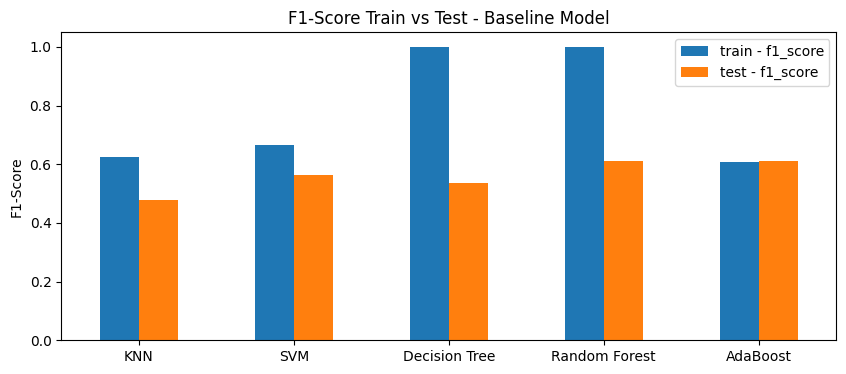

In [34]:
# Visualisasi perbandingan F1-score train vs test setiap model
baseline_df = pd.DataFrame(all_reports).T[['train - f1_score', 'test - f1_score']]
baseline_df.plot(kind='bar', figsize=(10,4))
plt.title('F1-Score Train vs Test - Baseline Model')
plt.ylabel('F1-Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.show()
                 

**Analisis Baseline Model:**

| Model | F1 Train | F1 Test | Kondisi |
|---|---|---|---|
| Decision Tree | 1.000 | 0.538 | Overfit, menghafal data train |
| Random Forest | 1.000 | 0.612 | Overfit, menghafal data train |
| KNN | 0.624 | 0.477 | Gap ±0.1 |
| SVM | 0.666 | 0.565 | Gap ±0.1 |
| AdaBoost | 0.608 | 0.610 | Good-fit (paling stabil) |

* **Masalah utama: recall rendah.** Semua model hanya mengenali ≤ 54% pembeli, artinya hampir separuh calon pembeli terlewat. Penyebabnya data imbalanced, sedangkan hyperparameter default tidak memberi bobot lebih pada kelas minoritas.
* **Potensinya tetap ada.** ROC-AUC Random Forest (0.916) dan AdaBoost (0.912) sudah tinggi, artinya model mampu membedakan sesi beli dan tidak beli. Hal ini akan diperbaiki lewat hyperparameter tuning.

### 8.2 Hasil Cross Validation dan Pemilihan Model Terbaik

In [35]:
# Rangkuman hasil cross validation
cv_summary = pd.DataFrame({
    'CV F1 Mean': {name: score.mean() for name, score in cv_scores.items()},
    'CV F1 Std': {name: score.std() for name, score in cv_scores.items()}
}).sort_values('CV F1 Mean', ascending=False).round(4)
cv_summary

,CV F1 Mean,CV F1 Std
Random Forest,0.6368,0.0184
AdaBoost,0.6235,0.0215
SVM,0.6078,0.0284
Decision Tree,0.5641,0.0132
KNN,0.5149,0.0168


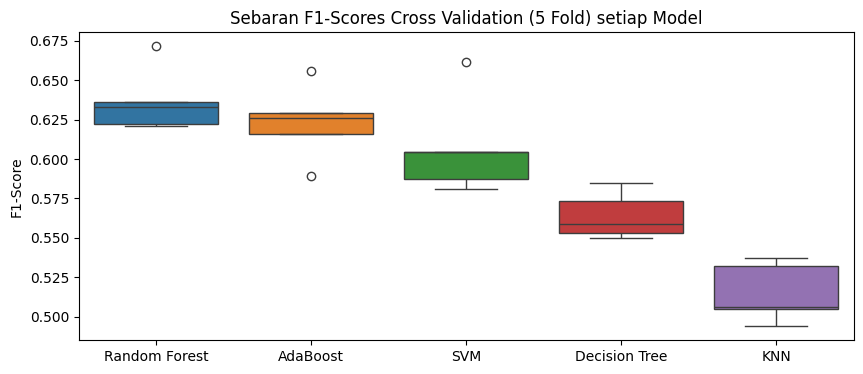

In [36]:
# Visualisasi sebaran F1-score setiap fold
plt.figure(figsize=(10, 4))
sns.boxplot(data=pd.DataFrame(cv_scores)[cv_summary.index])
plt.title('Sebaran F1-Scores Cross Validation (5 Fold) setiap Model')
plt.ylabel('F1-Score')
plt.show()

**Pemilihan Model Terbaik: Random Forest**
* F1-score cross validation-nya paling tinggi (**0.6368**) dan stabil di setiap fold (std 0.0184).
* Hasilnya sejalan dengan F1-score test, di mana Random Forest juga tertinggi (0.612).
* Model ini selanjutnya di-tuning untuk mengatasi overfit dan recall yang rendah.

### 8.3 Hasil Hyperparameter Tuning 

In [37]:
# Mendapatkan hyperparameters & score terbaik
print('Best Hyperparameters:', rf_randomcv.best_params_)
print('Best CV Score (F1) :', round(rf_randomcv.best_score_, 4))
print('CV Score Baseline :', round(cv_scores['Random Forest'].mean(), 4))

Best Hyperparameters: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 15, 'model__class_weight': 'balanced'}
Best CV Score (F1) : 0.6857
CV Score Baseline : 0.6368


In [38]:
# 10 kombinasi hyperparameter terbaik dari Random Search
cv_result = pd.DataFrame(rf_randomcv.cv_results_)
cv_result = cv_result[['param_model__n_estimators', 'param_model__max_depth', 'param_model__min_samples_split',
                       'param_model__min_samples_leaf', 'param_model__max_features', 'param_model__class_weight',
                       'mean_test_score', 'std_test_score', 'rank_test_score'
]]

cv_result.sort_values('rank_test_score').head(10)

,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
2,100,15,10,1,sqrt,balanced,0.685685,0.016526,1
10,300,20,10,2,sqrt,balanced,0.685676,0.013442,2
15,500,None,2,2,log2,balanced,0.683866,0.012362,3
6,200,15,5,1,log2,balanced,0.683742,0.009854,4
11,100,None,5,5,sqrt,balanced_subsample,0.683029,0.014548,5
16,200,20,5,5,sqrt,balanced,0.679035,0.016309,6
1,300,20,10,5,log2,balanced,0.677919,0.016129,7
20,300,None,2,5,log2,balanced_subsample,0.677067,0.017022,8
21,300,15,2,5,log2,balanced,0.676433,0.015164,9
25,500,20,5,1,log2,balanced,0.676160,0.014054,10


In [39]:
# Get best estimator 
rf_randomcv_best = rf_randomcv.best_estimator_

# Model Evaluation - Test-Set sebelum vs setelah tuning
print('Test-Set - Sebelum Tuning')
print(classification_report(y_test, pipe_rf.predict(X_test_selected)))
print('Test-Set - Setelah Tuning')
print(classification_report(y_test, rf_randomcv_best.predict(X_test_selected)))

Test-Set - Sebelum Tuning
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      2084
           1       0.74      0.52      0.61       382

    accuracy                           0.90      2466
   macro avg       0.83      0.74      0.78      2466
weighted avg       0.89      0.90      0.89      2466

Test-Set - Setelah Tuning
              precision    recall  f1-score   support

           0       0.95      0.91      0.93      2084
           1       0.60      0.72      0.65       382

    accuracy                           0.88      2466
   macro avg       0.77      0.82      0.79      2466
weighted avg       0.89      0.88      0.89      2466



In [40]:
# Rangkuman performa sebelum vs setelah tuning
all_reports = performance_report(all_reports, rf_randomcv_best, X_train_selected, y_train, X_test_selected, y_test, 'Random Forest Tuned')
pd.DataFrame(all_reports)[['Random Forest', 'Random Forest Tuned']].round(3)

,Random Forest,Random Forest Tuned
train - recall,1.000,0.936
test - recall,0.524,0.720
train - precision,1.000,0.731
test - precision,0.735,0.598
train - f1_score,1.000,0.821
test - f1_score,0.612,0.653
train - roc_auc,1.000,0.988
test - roc_auc,0.916,0.923


**Confusion Matrix & ROC Curve sebelum vs setelah tuning**

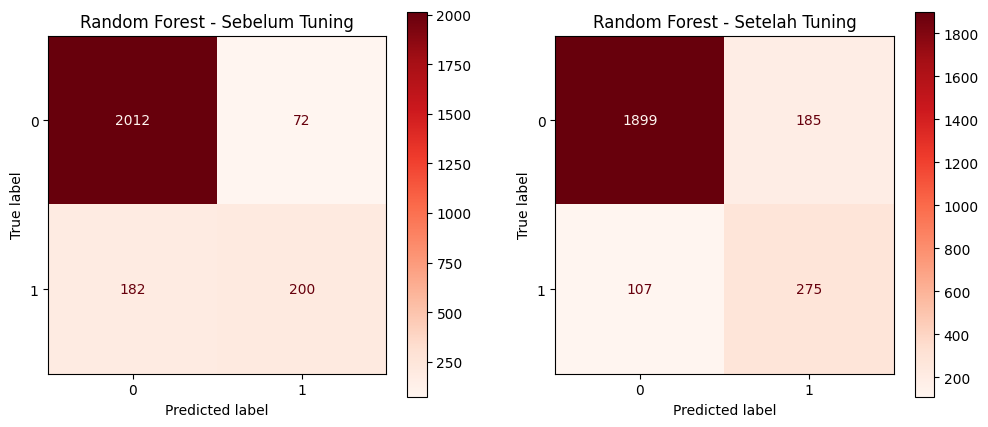

In [41]:
# Confusion Matrix - Test-Set
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(pipe_rf, X_test_selected, y_test, cmap='Reds', ax=axes[0])
axes[0].set_title('Random Forest - Sebelum Tuning')
ConfusionMatrixDisplay.from_estimator(rf_randomcv_best, X_test_selected, y_test, cmap='Reds', ax=axes[1])
axes[1].set_title('Random Forest - Setelah Tuning')
plt.show()

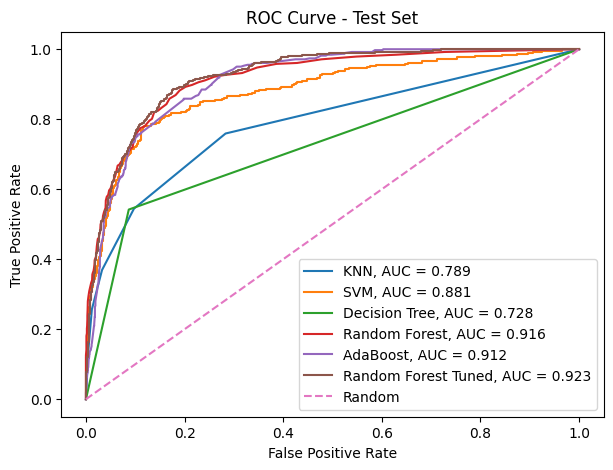

In [42]:
# Fungsi untuk membuat ROC curve beberapa model sekaligus
def plot_roc(models, X_test, y_test):
    plt.figure(figsize=(7, 5))
    for name, model in models.items():
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name}, AUC = {auc:.3f}')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - Test Set')
    plt.legend(loc=0)
    plt.show()

# ROC Curve seluruh baseline model dan model hasil tuning
plot_roc({**models, 'Random Forest Tuned': rf_randomcv_best}, X_test_selected, y_test)

**Analisis Hyperparameter Tuning:**
* **F1-score cross validation naik dari 0.6368 menjadi 0.6857.** Faktor terbesarnya adalah `class_weight='balanced'`, yang membuat model lebih memperhatikan sesi pembeli.

| Metrik (test) | Sebelum Tuning | Setelah Tuning |
|---|---|---|
| Recall | 0.524 | 0.720 |
| Precision | 0.735 | 0.598 |
| F1-score | 0.612 | 0.653 |
| ROC-AUC | 0.916 | 0.923 |

* **Trade-off:** model menangkap lebih banyak pembeli (275 dari 382), tetapi sesi yang salah diprediksi membeli juga bertambah (185).
* **Overfit berkurang** (F1 train 1.000 → 0.821), tetapi masih sedikit overfit.
* **Dampak bisnis:** dari 100 sesi yang diberi promo, ±60 benar-benar membeli, sekitar 3,9x lebih efisien dibanding promo acak (15.5%).

### Analisis Keseluruhan Model

**Kelebihan:**
* Mengenali **72%** sesi pembeli, dan promo **±3,9x lebih tepat sasaran** dibanding promo acak.

**Kelemahan:**
* **40%** sesi yang diprediksi membeli ternyata tidak membeli, dan **28%** pembeli masih terlewat.
* Masih sedikit overfit (F1 train 0.821 vs test 0.653).

**Improvement:**
* Menyesuaikan threshold sesuai budget promo, menambah fitur perilaku (misalnya produk di keranjang), dan mencoba algoritma boosting lain.

---
# 9. Model Saving

**Model terbaik: Random Forest hasil tuning**
* F1-score tertinggi, baik saat cross validation (0.686) maupun test (0.653).
* Recall tertinggi (0.720), sehingga paling banyak mengenali calon pembeli.
* Overfit berkurang dibanding versi default (F1 train 1.000 → 0.821).

**File yang disimpan:**
* `model_rf_tuned.pkl`: pipeline lengkap (capping, scaling, encoding, dan model) dalam satu file.
* `list_top_categories.txt`: daftar kategori hasil handling cardinality, dipakai saat inference dan deployment.

In [43]:
# Simpan model terbaik (Pipeline lengkap : Winsorizer + preprocessing + model)
with open('../src/model_rf_tuned.pkl', 'wb') as file_1:
    pickle.dump(rf_randomcv_best, file_1)

# Simpan daftar kategori hasil handling cardinality
list_top_categories = {
    'OperatingSystems': top_os,
    'TrafficType' : top_traffic
}
with open('../src/list_top_categories.txt', 'w') as file_2:
    json.dump(list_top_categories, file_2)

print('Model dan file pendukung berhasil disimpan')

Model dan file pendukung berhasil disimpan


--- 
# 10. Model Inference
* Model Inference dilakukan pada notebook terpisah: **P1M2_Baihaqsani_inf.ipynb**

---
# 11. Pengambilan Kesimpulan

**Kesimpulan:** 
1. **Ciri sesi yang membeli:** membuka lebih banyak halaman produk, lebih lama di halaman produk, dan mengunjungi halaman bernilai (`PageValues` > 0). Conversion tertinggi terjadi pada bulan November (25.4%).
2. **Model terbaik:** Random Forest, terpilih dari 5 algoritma lewat cross validation, lalu ditingkatkan dengan hyperparameter tuning (F1-score 0.637 → 0.686).
3. **Hasil model:** mengenali 72% sesi pembeli, dan promo jadi ±3,9x lebih tepat sasaran dibanding promo acak.
4. **Syarat pemakaian:** toko perlu mengaktifkan e-commerce tracking di Google Analytics, karena `PageValues` adalah fitur terpenting.

**Rekomendasi Bisnis:**
* Prioritaskan promo untuk sesi dengan probabilitas membeli tinggi.
* Fokuskan anggaran promo pada September-November, saat pengunjung paling siap membeli.